# Imports

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from collections import Counter

# Dataset Preparation

In [ ]:
# Load the SMS dataset
file_path = "/content/sms.csv"

# Read the dataset
df = pd.read_csv(
    file_path,
    sep=",",
    header=0,
    encoding="utf-8"
)

# Display the first five records
display(df.head())

print("Dataset shape:", df.shape)
print("\nClass distribution:")
print(df["label"].value_counts())


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


Dataset shape: (5572, 2)

Class distribution:
label
ham     4825
spam     747
Name: count, dtype: int64


## Dataset Preparation and Train/Validation/Test Split

The SMS dataset contains two columns: `label` and `message`. Each message is assigned to one of two classes: `ham`  or `spam`.

First, all messages are shuffled using the specified random generator, `np.random.default_rng(0)`, to ensure reproducibility. The dataset is then divided into three disjoint subsets:

- Training set: the first 75% of the first 80% of the shuffled dataset.
- Validation set: the remaining 25% of the first 80%.
- Test set: the final 20% of the shuffled dataset.

The training set is used to build the vocabulary and estimate the Naive Bayes parameters. The validation set is reserved for selecting the Neyman–Pearson threshold, while the test set is kept for final evaluation.

**Observed dataset sizes:**

- Total messages: 5,572
- Training messages: 3,342
- Validation messages: 1,115
- Test messages: 1,115

The three subsets are disjoint, so the validation and test messages do not contribute to vocabulary construction or model training.

In [ ]:
messages = df["message"].to_numpy()
labels = df["label"].to_numpy()

# Get the total number of messages
N = len(messages)

# Shuffle the dataset using the specified random generator
perm = np.random.default_rng(0).permutation(N)

# Apply the shuffled order
messages = messages[perm]
labels = labels[perm]

# Calculate split sizes
n_train_val = int(np.floor(0.8 * N))
n_train = int(np.floor(0.75 * n_train_val))

# Split the dataset
X_train = messages[:n_train]
y_train = labels[:n_train]

X_val = messages[n_train:n_train_val]
y_val = labels[n_train:n_train_val]

X_test = messages[n_train_val:]
y_test = labels[n_train_val:]

print("Total messages:", N)
print("Training set:", len(X_train))
print("Validation set:", len(X_val))
print("Test set:", len(X_test))


Total messages: 5572
Training set: 3342
Validation set: 1115
Test set: 1115


# Part (a): Vocabulary and Count Matrix

In [ ]:
# Tokenize a message
def tokenize(message):
    message = message.lower()
    return message.split()

word_document_counts = Counter()
for message in X_train:
    unique_words = set(tokenize(message))
    word_document_counts.update(unique_words)

# Build vocabulary
vocabulary = sorted([
    word
    for word, count in word_document_counts.items()
    if count >= 5])

# Create a mapping from words to column indices
word_to_index = {
    word: index
    for index, word in enumerate(vocabulary)
}

print("Vocabulary size:", len(vocabulary))

Vocabulary size: 1363


In [ ]:
# Convert a collection of messages into a count matrix
def build_count_matrix(messages, vocabulary, word_to_index):

    # Initialize the count matrix with zeros
    matrix = np.zeros(
        (len(messages), len(vocabulary)),
        dtype=np.int64
    )

    # Process each message
    for i, message in enumerate(messages):
        tokens = tokenize(message)
        word_counts = Counter(tokens)
        for word, count in word_counts.items():
            if word in word_to_index:
                j = word_to_index[word]
                matrix[i, j] = count

    return matrix


# Build count matrices for all three datasets

X_train_counts = build_count_matrix(X_train, vocabulary, word_to_index)
X_val_counts = build_count_matrix(X_val, vocabulary, word_to_index)
X_test_counts = build_count_matrix(X_test, vocabulary, word_to_index)

print("Training matrix shape:", X_train_counts.shape)
print("Validation matrix shape:", X_val_counts.shape)
print("Test matrix shape:", X_test_counts.shape)


Training matrix shape: (3342, 1363)
Validation matrix shape: (1115, 1363)
Test matrix shape: (1115, 1363)


The first step is to construct a vocabulary using only the training messages. Each message is converted to lowercase and tokenized by splitting it on whitespace.

To determine the vocabulary, document frequency is used rather than total word frequency. For each message, a set of unique words is created, and the document count of each word is updated. A word is included in the vocabulary only if it appears in at least five different training messages.

This filtering strategy removes rare words, including many typing errors and one-off phone numbers, while retaining frequently occurring terms.

Vocabulary size: 1,363 words.

Next, a word-count matrix is constructed for each 3 dataset. Each row represents a message, and each column corresponds to a word in the training vocabulary. The matrix entry represents the number of times that word occurs in the corresponding message.

The resulting matrix dimensions are:

Training: 3,342 × 1,363

Validation: 1,115 × 1,363

Test: 1,115 × 1,363

Importantly, the vocabulary is constructed exclusively from the training set. The same vocabulary is then applied to the validation and test sets. Words not present in the training vocabulary are ignored.

This guarantees that validation and test information does not leak into vocabulary construction.

# Part (b): Multinomial Naive Bayes

In [ ]:
# Laplace smoothing parameter
alpha = 1.0
classes = ["ham", "spam"]

# Initialize dictionaries for model parameters
log_priors = {}
log_likelihoods = {}

n_samples = len(y_train)

# Calculate prior and likelihood for each class
for c in classes:
    class_mask = (y_train == c)

    class_count = np.sum(class_mask)
    prior = class_count / n_samples

    log_priors[c] = np.log(prior)

    class_word_counts = X_train_counts[class_mask].sum(axis=0)
    total_words = class_word_counts.sum()

    # Laplace smoothing
    likelihoods = (
        class_word_counts + alpha
        ) / (total_words + alpha * len(vocabulary)
    )

    # Store log probabilities
    log_likelihoods[c] = np.log(likelihoods)


print("Log priors:")
for c in classes:
    print(c, log_priors[c])

print("\nLog likelihood shapes:")
for c in classes:
    print(c, log_likelihoods[c].shape)


Log priors:
ham -0.14600520914262213
spam -1.996227511113991

Log likelihood shapes:
ham (1363,)
spam (1363,)


In [ ]:
# Calculate log scores for each class
def calculate_log_scores(X_counts, log_priors, log_likelihoods):

    scores = {}
    for c in classes:
        # Calculate the log posterior score
        scores[c] = (
            log_priors[c]
            + X_counts @ log_likelihoods[c]
        )

    return scores


# Calculate log posterior odds
def calculate_log_odds(X_counts):

    scores = calculate_log_scores(
        X_counts,
        log_priors,
        log_likelihoods
    )

    # Calculate spam score minus ham score
    log_odds = scores["spam"] - scores["ham"]

    return log_odds


# Predict class labels
def predict_from_log_odds(log_odds, threshold=0.0):

    predictions = np.where(
        log_odds > threshold,
        "spam",
        "ham"
    )

    return predictions


# Calculate test log odds
test_log_odds = calculate_log_odds(X_test_counts)

# Predict test labels using the default threshold
y_test_pred = predict_from_log_odds(
    test_log_odds,
    threshold=0.0
)

print("First 10 predictions:")
print(y_test_pred[:10])


First 10 predictions:
['ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham']


### Test Accuracy

In [ ]:
# Calculate test accuracy
accuracy = np.mean(y_test_pred == y_test)

print(f"Test Accuracy: {accuracy:.4f}")
print(f"Test Accuracy (%): {accuracy * 100:.2f}%")


Test Accuracy: 0.9794
Test Accuracy (%): 97.94%


# Multinomial Naive Bayes with Laplace Smoothing

After constructing the word-count matrices, a Multinomial Naive Bayes classifier is implemented from scratch.

The model estimates two main types of probabilities using only the training set:

Class prior probabilities, representing the probability of each class before observing a message.

Word likelihood probabilities, representing the probability of observing each word given a particular class.

Laplace smoothing with $\alpha=1$ is applied to the word likelihoods. This prevents zero probabilities for words that do not occur in a particular class.

The probability estimates are converted into logarithmic form. Therefore, instead of multiplying many small probabilities, the classifier sums their logarithms:

$$
\log P(c|x) = \log P(c) + \sum_j x_j\log P(w_j|c) + C
$$

where $x_j$ is the count of word $j$ in the message, and $C$ is a class-independent normalization constant.

The spam decision is based on the log posterior odds:

$$
L(x)=\log P(spam|x)-\log P(ham|x)
$$

Using the default threshold of zero, the classifier predicts spam when $L(x)>0$, and ham otherwise.

The estimated log prior probabilities are:

Ham: -0.1460

Spam: -1.9962

Test accuracy: 97.94%.

The high test accuracy indicates that the model can distinguish legitimate and promotional messages effectively. However, accuracy alone does not fully describe the classifier's ability to identify spam, especially because the dataset contains substantially more ham messages than spam messages. Therefore, precision, recall, and F1-score are examined in the following sections.

# Part(c): Words Associated with Spam

In [ ]:
# Calculate log probability ratios for all vocabulary words
log_word_ratios = (
    log_likelihoods["spam"]
    - log_likelihoods["ham"]
)

# Get indices of the 5 words with the highest ratios
top_5_indices = np.argsort(log_word_ratios)[-5:][::-1]

print("Top 5 words associated with spam:\n")

for index in top_5_indices:
    word = vocabulary[index]
    ratio = log_word_ratios[index]
    print(f"{word:20s} {ratio:.4f}")


Top 5 words associated with spam:

claim                5.4546
won                  5.0251
prize                4.7772
urgent!              4.6437
awarded              4.5696


To identify the words that most strongly indicate spam, the logarithm of the ratio between the spam and ham word likelihoods is calculated for every vocabulary word:

$$
R(w)=\log\frac{P(w|spam)}{P(w|ham)}
$$

A higher positive value indicates that a word is more strongly associated with spam than with legitimate messages.

The five words with the highest log probability ratios are:

| Rank | Word | Log Probability Ratio |
| :---: | :--- | :---: |
| 1 | claim | 5.4546 |
| 2 | won | 5.0251 |
| 3 | prize | 4.7772 |
| 4 | urgent! | 4.6437 |
| 5 | awarded | 4.5696 |

These results are consistent with common promotional and prize-related spam patterns.

For example, words such as claim, won, prize, and awarded frequently appear in messages that announce winnings or encourage recipients to claim rewards.

The positive and relatively large log ratios indicate that these words have substantially higher estimated probabilities in spam messages than in ham messages.

Therefore, these words provide strong evidence in favor of the spam class when they appear in a message.

# Part(d): Confusion Matrix and Evaluation Metrics

In [ ]:
# Calculate confusion matrix
def calculate_confusion_matrix(y_true, y_pred):

    TP = np.sum((y_true == "spam") & (y_pred == "spam"))
    TN = np.sum((y_true == "ham") & (y_pred == "ham"))
    FP = np.sum((y_true == "ham") & (y_pred == "spam"))
    FN = np.sum((y_true == "spam") & (y_pred == "ham"))

    return np.array([
        [TN, FP],
        [FN, TP]
    ])


# Calculate the test confusion matrix
conf_matrix = calculate_confusion_matrix(
    y_test,
    y_test_pred
)

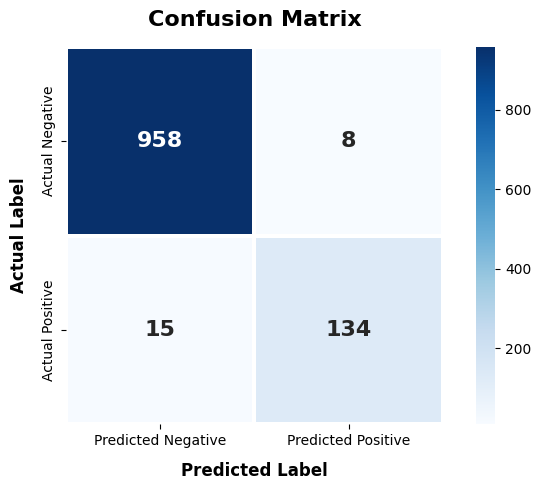

In [ ]:
# Plot Confusion Matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    conf_matrix,
    annot=True,
    fmt='d',
    cmap='Blues',
    linewidths=1.5,
    linecolor='white',
    cbar=True,
    square=True,
    annot_kws={"size": 16, "weight": "bold"},
    xticklabels=['Predicted Negative', 'Predicted Positive'],
    yticklabels=['Actual Negative', 'Actual Positive']
)

plt.title('Confusion Matrix', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Predicted Label', fontsize=12, fontweight='bold', labelpad=10)
plt.ylabel('Actual Label', fontsize=12, fontweight='bold', labelpad=10)

plt.tight_layout()
plt.show()

In [ ]:
TN, FP = conf_matrix[0]
FN, TP = conf_matrix[1]

# Calculate precision, recall and F1 score
precision = TP / (TP + FP) if (TP + FP) > 0 else 0.0
recall = TP / (TP + FN) if (TP + FN) > 0 else 0.0
f1_score = (
    2 * precision * recall / (precision + recall)
    if (precision + recall) > 0
    else 0.0
)
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1_score:.4f}")


Precision: 0.9437
Recall:    0.8993
F1 Score:  0.9210


The classifier is evaluated on the test set using the default decision threshold of zero.
The confusion matrix is:

$$
\begin{bmatrix}
958 & 8 \\
15 & 134
\end{bmatrix}
$$

The rows represent actual classes, while the columns represent predicted classes.
Therefore:
- True Negatives (TN) = 958
- False Positives (FP) = 8
- False Negatives (FN) = 15
- True Positives (TP) = 134

The test set contains 966 legitimate messages and 149 spam messages.
The classifier correctly identifies 134 out of 149 actual spam messages. However, 15 spam messages are incorrectly classified as ham.

The evaluation metrics are calculated as follows:

$$
Precision=\frac{TP}{TP+FP}=0.9437
$$

$$
Recall=\frac{TP}{TP+FN}=0.8993
$$

$$
F1=\frac{2(Precision)(Recall)}{Precision+Recall}=0.9210
$$

The resulting precision is 94.37%, meaning that most messages classified as spam are actually spam.
The spam recall is 89.93%, meaning that approximately 90% of all actual spam messages are detected.

Although the classifier achieves a high accuracy of 97.94%, it still misses 15 spam messages. This demonstrates why recall is particularly important for evaluating a spam filter, especially when missed spam messages are undesirable.

# Part (e)

In [ ]:
# Calculate TPR and FPR
def calculate_tpr_fpr(y_true, log_odds, threshold):
    # Predict spam when log odds exceeds the threshold
    y_pred = np.where(log_odds > threshold, "spam", "ham")

    # Calculate confusion matrix components
    TP = np.sum((y_true == "spam") & (y_pred == "spam"))
    FN = np.sum((y_true == "spam") & (y_pred == "ham"))

    FP = np.sum((y_true == "ham") & (y_pred == "spam"))
    TN = np.sum((y_true == "ham") & (y_pred == "ham"))

    # Calculate TPR (Recall)
    TPR = TP / (TP + FN) if (TP + FN) > 0 else 0.0

    # Calculate FPR
    FPR = FP / (FP + TN) if (FP + TN) > 0 else 0.0

    return FPR, TPR

In [ ]:
# Get all unique log odds scores
unique_thresholds = np.unique(test_log_odds)

thresholds = np.sort(unique_thresholds)[::-1]

# Initialize lists for ROC coordinates
fpr_values = []
tpr_values = []

for threshold in thresholds:
    fpr, tpr = calculate_tpr_fpr(
        y_test,
        test_log_odds,
        threshold
    )

    fpr_values.append(fpr)
    tpr_values.append(tpr)


# Convert lists to NumPy arrays
fpr_values = np.array(fpr_values)
tpr_values = np.array(tpr_values)

# Add the two endpoints of the ROC curve
fpr_values = np.concatenate(([0.0], fpr_values, [1.0]))
tpr_values = np.concatenate(([0.0], tpr_values, [1.0]))

print("Number of ROC points:", len(fpr_values))


Number of ROC points: 1067


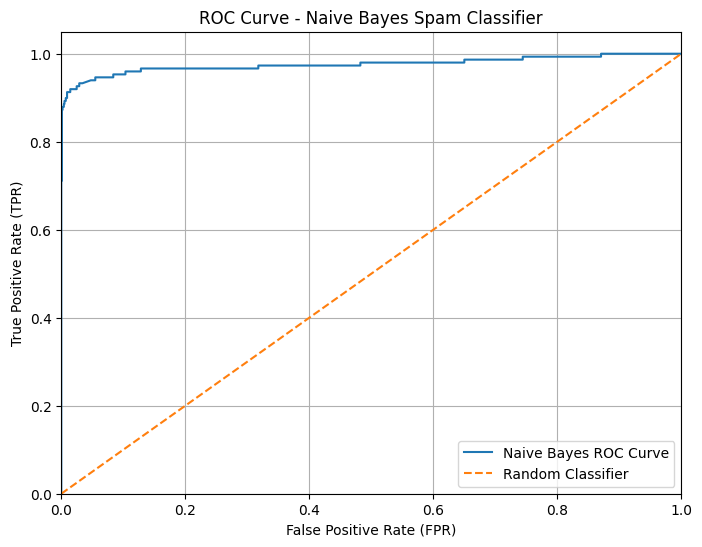

In [ ]:
plt.figure(figsize=(8, 6))

plt.plot(
    fpr_values,
    tpr_values,
    label="Naive Bayes ROC Curve"
)

# Plot the random classifier baseline
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.title("ROC Curve - Naive Bayes Spam Classifier")

plt.xlim(0, 1)
plt.ylim(0, 1.05)

plt.grid(True)
plt.legend()
plt.show()

In [ ]:
# Calculate AUC using the trapezoidal rule
auc_trapezoid = np.trapezoid(
    tpr_values,
    fpr_values
)

print(f"AUC (Trapezoidal Rule): {auc_trapezoid:.6f}")

AUC (Trapezoidal Rule): 0.975791


In [ ]:
# Separate prediction scores according to their true classes
spam_scores = test_log_odds[y_test == "spam"]
ham_scores = test_log_odds[y_test == "ham"]

n_spam = len(spam_scores)
n_ham = len(ham_scores)

comparisons = spam_scores[:, np.newaxis] - ham_scores[np.newaxis, :]
n_greater = np.sum(comparisons > 0)
n_equal = np.sum(comparisons == 0)

# Calculate AUC using pairwise comparisons
auc_pairwise = (
    n_greater + 0.5 * n_equal
) / (
    n_spam * n_ham
)

print(f"Number of spam messages: {n_spam}")
print(f"Number of ham messages: {n_ham}")
print(f"Total number of pairs: {n_spam * n_ham}")

print(f"\nPairs where spam score is higher: {n_greater}")
print(f"Pairs with equal scores: {n_equal}")

print(f"\nAUC (Pairwise Comparison): {auc_pairwise:.6f}")


Number of spam messages: 149
Number of ham messages: 966
Total number of pairs: 143934

Pairs where spam score is higher: 140443
Pairs with equal scores: 13

AUC (Pairwise Comparison): 0.975791


In [ ]:
auc_difference = abs(auc_trapezoid - auc_pairwise)

print(f"AUC (Trapezoidal): {auc_trapezoid:.8f}")
print(f"AUC (Pairwise):    {auc_pairwise:.8f}")

print(f"\nAbsolute difference: {auc_difference:.12f}")

if np.isclose(auc_trapezoid, auc_pairwise, atol=1e-10):
    print("Both AUC calculations agree.")
else:
    print("The AUC calculations do not agree. Check the ROC construction.")

AUC (Trapezoidal): 0.97579099
AUC (Pairwise):    0.97579099

Absolute difference: 0.000000000000
Both AUC calculations agree.


To evaluate the classifier at different decision thresholds, a Receiver Operating Characteristic (ROC) curve is constructed using the test-set log posterior odds.
For each candidate threshold, the True Positive Rate (TPR) and False Positive Rate (FPR) are calculated:

$$
TPR=\frac{TP}{TP+FN}
$$

$$
FPR=\frac{FP}{FP+TN}
$$

By varying the threshold, different classification operating points are obtained and used to construct the ROC curve.
The Area Under the Curve (AUC) is calculated using two independent approaches.

1. Trapezoidal Rule
The area under the ROC curve is computed numerically using the trapezoidal rule:

$$
AUC_{trapezoidal}=0.975791
$$

2. Pairwise Comparison
Each spam message is compared with every ham message. The total number of pairs is:

$$
149\times966=143934
$$

The results are:
- Spam score higher than ham score: 140,443 pairs.
- Equal spam and ham scores: 13 pairs.

The fraction of pairs in which the spam score is strictly higher is:

$$
\frac{140443}{143934}=0.975746
$$

For the conventional pairwise AUC calculation, tied pairs receive half credit:

$$
AUC_{pairwise}=\frac{140443+0.5(13)}{143934}=0.975791
$$

Both AUC methods produce the same result:

$$
AUC_{pairwise} = AUC_{trapezoidal} = 0.975791
$$

This agreement confirms the consistency of the ROC-based and pairwise AUC calculations.
The high AUC value indicates that the classifier has a strong ability to rank spam messages above legitimate messages across different decision thresholds.

# Part (f)

In [ ]:
# Calculate log posterior odds for validation messages
val_log_odds = calculate_log_odds(X_val_counts)

# Display the first 10 validation scores
print("First 10 validation log odds:")
print(val_log_odds[:10])

# Display validation class distribution
print("\nValidation class distribution:")
print(pd.Series(y_val).value_counts())

# Display the number of validation messages
print("\nNumber of validation messages:", len(y_val))

First 10 validation log odds:
[-14.13184806  19.98850692   1.54173486 -28.52858786 -19.46220908
  32.17741329 -11.36227212 -14.55521593  33.50916088  -4.70449029]

Validation class distribution:
ham     971
spam    144
Name: count, dtype: int64

Number of validation messages: 1115


In [ ]:
max_fpr = 0.01

# Get all unique validation scores
unique_val_scores = np.unique(val_log_odds)

# Generate thresholds just below each unique score
candidate_thresholds = np.nextafter(
    unique_val_scores,
    -np.inf
)

# Add a threshold that predicts every message as ham
candidate_thresholds = np.append(
    candidate_thresholds,
    np.max(val_log_odds)
)

# Remove duplicate thresholds and sort them
candidate_thresholds = np.unique(candidate_thresholds)

# Initialize lists to store evaluation results
validation_fpr = []
validation_tpr = []

# Evaluate every candidate threshold
for threshold in candidate_thresholds:
    fpr, tpr = calculate_tpr_fpr(
        y_val,
        val_log_odds,
        threshold
    )

    validation_fpr.append(fpr)
    validation_tpr.append(tpr)


# Convert results to NumPy arrays
validation_fpr = np.array(validation_fpr)
validation_tpr = np.array(validation_tpr)

# Identify thresholds satisfying the FPR constraint
feasible_indices = np.where(
    validation_fpr <= max_fpr
)[0]

# Find the maximum recall among feasible thresholds
best_recall = np.max(validation_tpr[feasible_indices])

# Find all thresholds achieving the maximum recall
best_indices = feasible_indices[
    validation_tpr[feasible_indices] == best_recall
]

# Among tied solutions, choose the one with the lowest FPR
best_index = best_indices[
    np.argmin(validation_fpr[best_indices])
]

# Store the selected threshold
best_threshold = candidate_thresholds[best_index]

# Display the selected threshold and its validation performance
print(f"Maximum allowed FPR: {max_fpr:.4f}")

print(f"\nSelected threshold: {best_threshold:.8f}")
print(f"Validation FPR: {validation_fpr[best_index]:.4f}")
print(f"Validation Recall: {validation_tpr[best_index]:.4f}")


Maximum allowed FPR: 0.0100

Selected threshold: 0.05153066
Validation FPR: 0.0062
Validation Recall: 0.8750


In [ ]:
# Apply the selected threshold to the test scores
y_test_pred_np = predict_from_log_odds(
    test_log_odds,
    threshold=best_threshold
)

# Calculate the confusion matrix on the test set
np_conf_matrix = calculate_confusion_matrix(
    y_test,
    y_test_pred_np
)

# Extract confusion matrix components
TN_np, FP_np = np_conf_matrix[0]
FN_np, TP_np = np_conf_matrix[1]

# Calculate test FPR
test_fpr_np = (
    FP_np / (FP_np + TN_np)
    if (FP_np + TN_np) > 0
    else 0.0
)

# Calculate test spam recall
test_recall_np = (
    TP_np / (TP_np + FN_np)
    if (TP_np + FN_np) > 0
    else 0.0
)

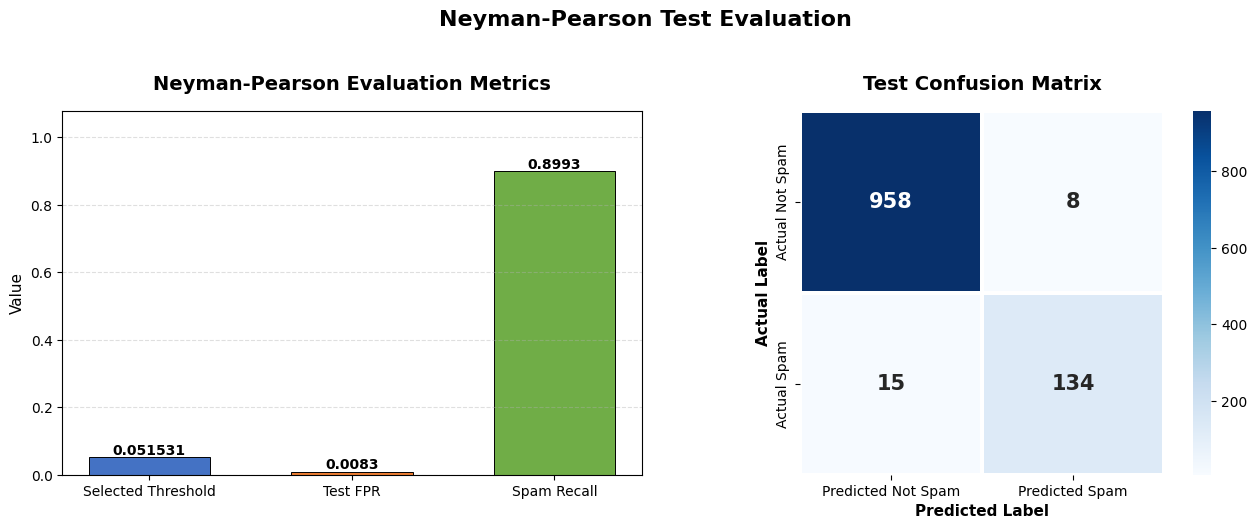

Neyman-Pearson Evaluation on Test Set
--------------------------------------
Selected Threshold: 0.05153066
Test FPR:            0.0083
Test Spam Recall:    0.8993

Confusion Matrix:
[[958   8]
 [ 15 134]]


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

metrics = {
    'Selected Threshold': best_threshold,
    'Test FPR': test_fpr_np,
    'Spam Recall': test_recall_np
}

metric_labels = list(metrics.keys())
metric_values = list(metrics.values())

bars = axes[0].bar(
    metric_labels,
    metric_values,
    color=['#4472C4', '#ED7D31', '#70AD47'],
    width=0.6,
    edgecolor='black',
    linewidth=0.7
)

axes[0].set_title('Neyman-Pearson Evaluation Metrics',
                  fontsize=14, fontweight='bold', pad=15)
axes[0].set_ylabel('Value', fontsize=11)
axes[0].set_ylim(0, max(metric_values) * 1.2)
axes[0].grid(axis='y', linestyle='--', alpha=0.4)

for bar, value in zip(bars, metric_values):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{value:.6f}' if value == best_threshold else f'{value:.4f}',
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold'
    )

sns.heatmap(
    np_conf_matrix,
    annot=True,
    fmt='d',
    cmap='Blues',
    linewidths=1.5,
    linecolor='white',
    cbar=True,
    square=True,
    annot_kws={"size": 15, "weight": "bold"},
    xticklabels=['Predicted Not Spam', 'Predicted Spam'],
    yticklabels=['Actual Not Spam', 'Actual Spam'],
    ax=axes[1]
)

axes[1].set_title('Test Confusion Matrix',
                  fontsize=14, fontweight='bold', pad=15)
axes[1].set_xlabel('Predicted Label', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Actual Label', fontsize=11, fontweight='bold')

fig.suptitle(
    'Neyman-Pearson Test Evaluation',
    fontsize=16,
    fontweight='bold',
    y=1.03
)

plt.tight_layout()
plt.show()

# Print numerical results
print("Neyman-Pearson Evaluation on Test Set")
print("--------------------------------------")
print(f"Selected Threshold: {best_threshold:.8f}")
print(f"Test FPR:            {test_fpr_np:.4f}")
print(f"Test Spam Recall:    {test_recall_np:.4f}")
print("\nConfusion Matrix:")
print(np_conf_matrix)

In [ ]:
default_threshold = 0.0

default_fpr = FP / (FP + TN) if (FP + TN) > 0 else 0.0
default_recall = recall

# Create a comparison table
comparison = pd.DataFrame({
    "Metric": [
        "Threshold",
        "False Positive Rate",
        "Spam Recall",
        "True Positives",
        "False Positives",
        "True Negatives",
        "False Negatives"
    ],

    "Default Threshold": [
        default_threshold,
        default_fpr,
        default_recall,
        TP,
        FP,
        TN,
        FN
    ],

    "Neyman-Pearson": [
        best_threshold,
        test_fpr_np,
        test_recall_np,
        TP_np,
        FP_np,
        TN_np,
        FN_np
    ]
})

# Display the comparison table
display(comparison)


,Metric,Default Threshold,Neyman-Pearson
0,Threshold,0.000000,0.051531
1,False Positive Rate,0.008282,0.008282
2,Spam Recall,0.899329,0.899329
3,True Positives,134.000000,134.000000
4,False Positives,8.000000,8.000000
5,True Negatives,958.000000,958.000000
6,False Negatives,15.000000,15.000000


In [ ]:

# Display validation and test FPR values
print(f"Validation FPR: {validation_fpr[best_index]:.4f}")
print(f"Test FPR:       {test_fpr_np:.4f}")

print(f"\nRequired maximum FPR: {max_fpr:.4f}")

# Check whether the constraint is satisfied on each dataset
validation_constraint_met = (
    validation_fpr[best_index] <= max_fpr
)

test_constraint_met = (
    test_fpr_np <= max_fpr
)

print("\nConstraint evaluation:")
print("Validation constraint satisfied:", validation_constraint_met)
print("Test constraint satisfied:", test_constraint_met)


Validation FPR: 0.0062
Test FPR:       0.0083

Required maximum FPR: 0.0100

Constraint evaluation:
Validation constraint satisfied: True
Test constraint satisfied: True


The objective of this section is to select a decision threshold that maximizes spam recall while constraining the false positive rate on legitimate messages to at most 1%.
Since legitimate messages are particularly important to protect from being incorrectly classified as spam, the threshold is selected using the validation set rather than the test set.
The optimization problem is:

$$
\max_t Recall_{spam}(t)
$$

subject to:

$$
FPR_{ham}(t)\leq0.01
$$

All candidate thresholds are evaluated on the validation set. Among the thresholds satisfying the FPR constraint, the one achieving the highest spam recall is selected. When multiple thresholds achieve the same maximum recall, the threshold with the lower FPR is preferred.

The selected threshold is:

$$
t^*=0.05153066
$$

Its validation performance is:
- Validation FPR: 0.0062 (0.62%)
- Validation spam recall: 0.8750 (87.50%)

The selected threshold satisfies the required maximum FPR of 1%.

### Evaluation on the Test Set

The selected threshold is then applied to the test set without any further adjustment.
The resulting confusion matrix is:

$$
\begin{bmatrix}
958 & 8 \\
15 & 134
\end{bmatrix}
$$

The test-set performance is:
- Test FPR: 0.0083 (0.83%)
- Test spam recall: 0.8993 (89.93%)

Therefore, the test-set FPR also remains below the required 1% limit.

### Comparison with the Default Threshold

The default classifier uses a threshold of zero, whereas the Neyman–Pearson method selects a threshold of 0.05153066.
Interestingly, both thresholds produce exactly the same test confusion matrix and classification metrics.
This happens because increasing the threshold from zero to 0.05153066 does not change any test prediction. In other words, there are no test messages with log posterior odds in the interval:

$$
0 < L(x) \leq 0.05153066
$$

Consequently, both methods classify exactly the same number of messages in each category.
The identical results do not mean that the two thresholds are mathematically equivalent. They simply produce the same decisions on this particular test set.

### Why the 1% Validation Constraint Does Not Guarantee the Same Future FPR

The 1% constraint is an empirical requirement measured on a finite validation sample. It does not guarantee that the true false positive rate on all future messages will remain below 1%.

There are two important reasons:
1. **Sampling variability:** The validation set contains only a limited number of legitimate messages. Therefore, its measured FPR is an estimate of the underlying error rate rather than an exact population value.
2. **Distribution shift:** Future messages may have different characteristics from those observed in the training and validation sets. Changes in legitimate messaging patterns can affect the classifier's false positive rate.

Thus, satisfying the constraint on the validation set provides evidence of good performance, but it is not a mathematical guarantee for tomorrow's messages.
The test-set result of 0.83% provides additional evidence that the selected threshold performs well on unseen data. However, continuous monitoring and possible recalibration may be necessary when the distribution of incoming messages changes.